In [ ]:

import pandas as pd
from google.colab import files

uploaded = files.upload()

file_name = list(uploaded.keys())[0]
df = pd.read_excel(file_name)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())


Saving hackathon_preli_dataset.xlsx to hackathon_preli_dataset.xlsx
Dataset loaded successfully!
Number of rows and columns: (31320, 12)

Column names:
['date', 'city', 'ward_id', 'population_density_sqkm', 'water_logging_risk_index', 'sanitation_score', 'avg_temp_c', 'max_temp_c', 'min_temp_c', 'rainfall_mm', 'relative_humidity_pct', 'dengue_cases']

First 5 rows:


,date,city,ward_id,population_density_sqkm,water_logging_risk_index,sanitation_score,avg_temp_c,max_temp_c,min_temp_c,rainfall_mm,relative_humidity_pct,dengue_cases
0,2016-01-04,Chattogram,CCC_Ward_01,64024,0.87,0.46,18.32,26.54,14.13,0.00,59.24,0
1,2016-01-11,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.24,26.95,16.71,2.02,61.63,0
2,2016-01-18,Chattogram,CCC_Ward_01,64024,0.87,0.46,20.94,25.05,14.84,0.00,60.50,0
3,2016-01-25,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.75,27.20,17.58,1.52,69.02,0
4,2016-02-01,Chattogram,CCC_Ward_01,64024,0.87,0.46,22.39,28.02,16.98,0.94,60.50,0


In [ ]:

print("DATA TYPES:")
print(df.dtypes)

print("\nMISSING VALUES:")
print(df.isnull().sum())

print("\nDUPLICATE ROWS:")
print(df.duplicated().sum())

df['date'] = pd.to_datetime(df['date'])

print("\nDATE RANGE:")
print("Starting date:", df['date'].min())
print("Ending date:", df['date'].max())

print("\nUNIQUE WARDS:", df['ward_id'].nunique())
print("UNIQUE CITIES:", df['city'].nunique())
print("\nCITY NAMES:")
print(df['city'].unique())


DATA TYPES:
date                        datetime64[ns]
city                                object
ward_id                             object
population_density_sqkm              int64
water_logging_risk_index           float64
sanitation_score                   float64
avg_temp_c                         float64
max_temp_c                         float64
min_temp_c                         float64
rainfall_mm                        float64
relative_humidity_pct              float64
dengue_cases                         int64
dtype: object

MISSING VALUES:
date                        0
city                        0
ward_id                     0
population_density_sqkm     0
water_logging_risk_index    0
sanitation_score            0
avg_temp_c                  0
max_temp_c                  0
min_temp_c                  0
rainfall_mm                 0
relative_humidity_pct       0
dengue_cases                0
dtype: int64

DUPLICATE ROWS:
0

DATE RANGE:
Starting date: 2016-01-04 00:00:00
E

In [ ]:


print("DENGUE CASE STATISTICS")
print(df['dengue_cases'].describe())

zero_cases = (df['dengue_cases'] == 0).sum()
nonzero_cases = (df['dengue_cases'] > 0).sum()

print("\nZERO-CASE RECORDS:", zero_cases)
print("NON-ZERO RECORDS:", nonzero_cases)

print("\nPERCENTAGE OF ZERO-CASE RECORDS:",
      round(zero_cases / len(df) * 100, 2), "%")

print("\nHIGHEST DENGUE CASE RECORDS:")
display(df.nlargest(10, 'dengue_cases')[
    ['date', 'city', 'ward_id', 'dengue_cases']
])


DENGUE CASE STATISTICS
count    31320.000000
mean         2.636398
std          4.607737
min          0.000000
25%          0.000000
50%          0.000000
75%          4.000000
max         41.000000
Name: dengue_cases, dtype: float64

ZERO-CASE RECORDS: 18176
NON-ZERO RECORDS: 13144

PERCENTAGE OF ZERO-CASE RECORDS: 58.03 %

HIGHEST DENGUE CASE RECORDS:


,date,city,ward_id,dengue_cases
25087,2016-08-08,Dhaka South,DSCC_Ward_19,41
11357,2023-07-31,Dhaka North,DNCC_Ward_12,39
1074,2016-08-01,Chattogram,CCC_Ward_03,38
26653,2016-08-08,Gazipur,GCC_Ward_02,34
31,2016-08-08,Chattogram,CCC_Ward_01,33
18301,2016-08-08,Dhaka South,DSCC_Ward_06,33
25086,2016-08-01,Dhaka South,DSCC_Ward_19,33
396,2023-08-07,Chattogram,CCC_Ward_01,32
14125,2016-08-08,Dhaka North,DNCC_Ward_18,32
14646,2016-08-01,Dhaka North,DNCC_Ward_19,32


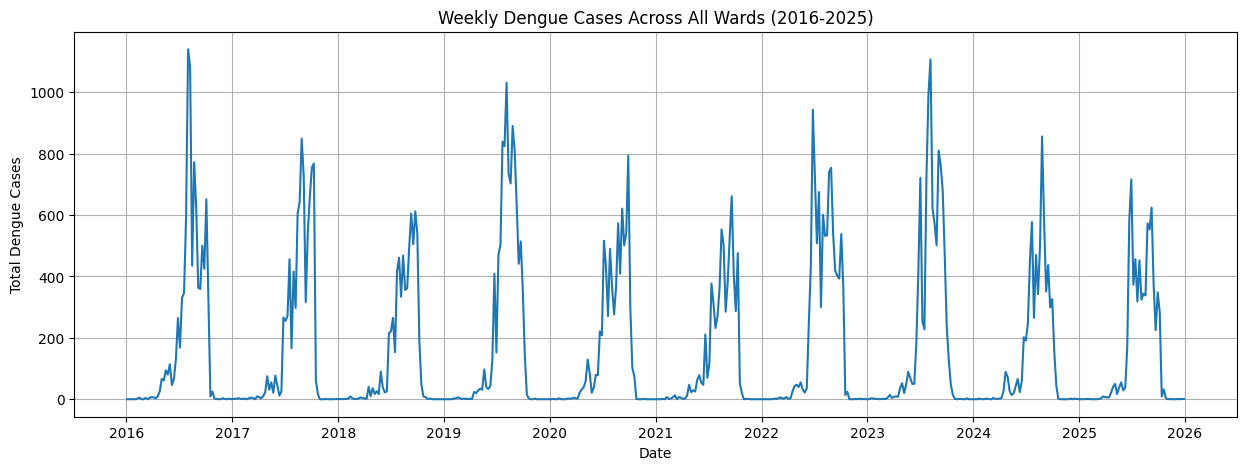

In [ ]:

import matplotlib.pyplot as plt

weekly_cases = df.groupby('date')['dengue_cases'].sum()

plt.figure(figsize=(15, 5))

plt.plot(weekly_cases.index, weekly_cases.values)

plt.title('Weekly Dengue Cases Across All Wards (2016-2025)')
plt.xlabel('Date')
plt.ylabel('Total Dengue Cases')
plt.grid(True)

plt.show()



AVERAGE WEEKLY DENGUE CASES BY MONTH:
date
1       0.511111
2       1.658537
3       3.790698
4      18.790698
5      50.533333
6     167.000000
7     411.355556
8     568.113636
9     508.930233
10    150.977778
11      0.428571
12      0.409091
Name: dengue_cases, dtype: float64


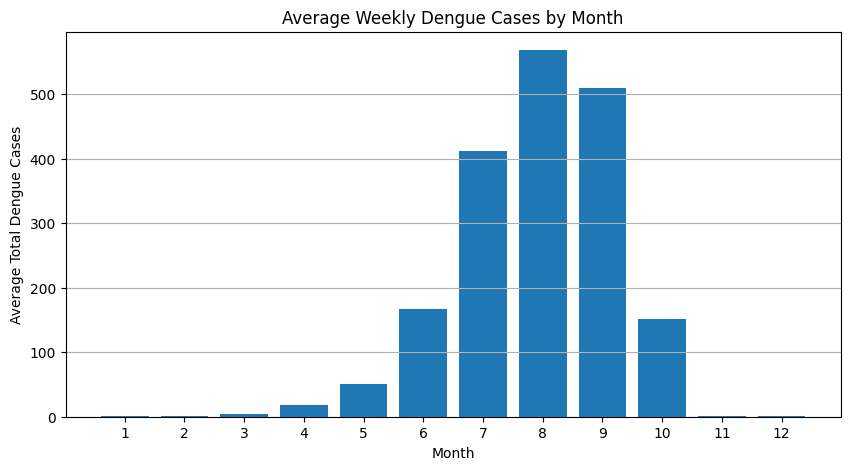

In [ ]:

df['month'] = df['date'].dt.month

weekly_total = df.groupby('date')['dengue_cases'].sum()

monthly_average = weekly_total.groupby(
    weekly_total.index.month
).mean()

print("AVERAGE WEEKLY DENGUE CASES BY MONTH:")
print(monthly_average)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(monthly_average.index, monthly_average.values)

plt.title('Average Weekly Dengue Cases by Month')
plt.xlabel('Month')
plt.ylabel('Average Total Dengue Cases')

plt.xticks(range(1, 13))
plt.grid(axis='y')

plt.show()


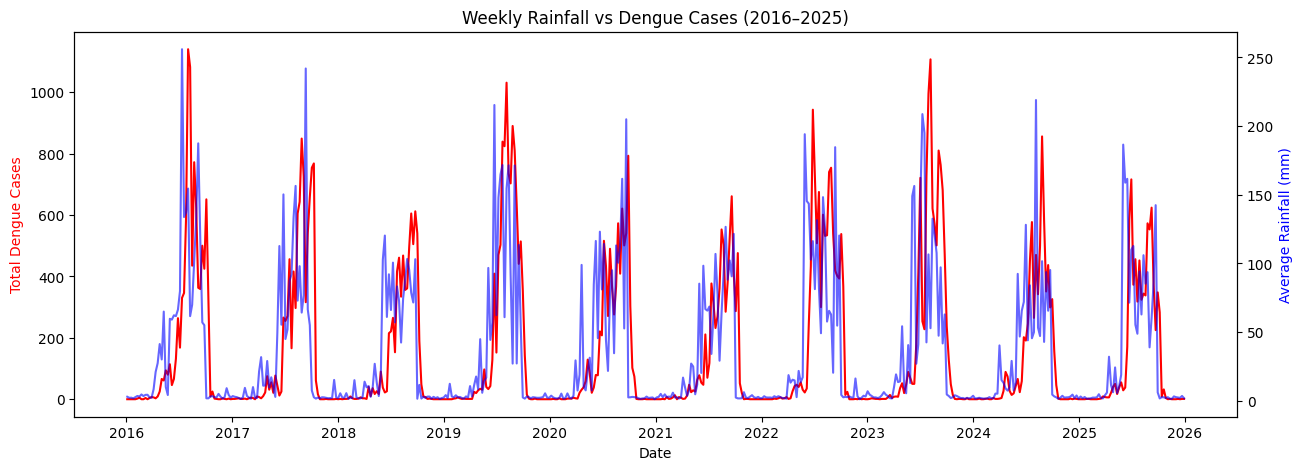

In [ ]:

import matplotlib.pyplot as plt

weekly_rainfall = df.groupby('date')['rainfall_mm'].mean()

weekly_dengue = df.groupby('date')['dengue_cases'].sum()

fig, ax1 = plt.subplots(figsize=(15, 5))

ax1.plot(
    weekly_dengue.index,
    weekly_dengue.values,
    color='red',
    label='Dengue Cases'
)

ax1.set_xlabel('Date')
ax1.set_ylabel('Total Dengue Cases', color='red')

ax2 = ax1.twinx()

ax2.plot(
    weekly_rainfall.index,
    weekly_rainfall.values,
    color='blue',
    alpha=0.6,
    label='Average Rainfall'
)

ax2.set_ylabel('Average Rainfall (mm)', color='blue')

plt.title('Weekly Rainfall vs Dengue Cases (2016–2025)')
plt.show()


In [ ]:

df = df.sort_values(['ward_id', 'date']).copy()

for lag in range(1, 5):
    df[f'rainfall_lag_{lag}'] = (
        df.groupby('ward_id')['rainfall_mm'].shift(lag)
    )

print("CORRELATION WITH DENGUE CASES:\n")

for lag in range(1, 5):
    correlation = df['dengue_cases'].corr(
        df[f'rainfall_lag_{lag}']
    )

    print(f"Rainfall {lag} week(s) earlier: {correlation:.4f}")


CORRELATION WITH DENGUE CASES:

Rainfall 1 week(s) earlier: 0.5913
Rainfall 2 week(s) earlier: 0.6722
Rainfall 3 week(s) earlier: 0.7501
Rainfall 4 week(s) earlier: 0.6807


In [ ]:


for horizon in [2, 3, 4]:

    future_cases = (
        df.groupby('ward_id')['dengue_cases'].shift(-horizon)
    )

    print(f"\nDENGUE PREDICTION: {horizon} WEEKS AHEAD")

    for lag in range(0, 5):

        if lag == 0:
            rainfall_feature = df['rainfall_mm']
        else:
            rainfall_feature = df[f'rainfall_lag_{lag}']

        correlation = rainfall_feature.corr(future_cases)

        print(
            f"Rainfall {lag} week(s) ago: {correlation:.4f}"
        )



DENGUE PREDICTION: 2 WEEKS AHEAD
Rainfall 0 week(s) ago: 0.6722
Rainfall 1 week(s) ago: 0.7501
Rainfall 2 week(s) ago: 0.6807
Rainfall 3 week(s) ago: 0.5420
Rainfall 4 week(s) ago: 0.4970

DENGUE PREDICTION: 3 WEEKS AHEAD
Rainfall 0 week(s) ago: 0.7501
Rainfall 1 week(s) ago: 0.6807
Rainfall 2 week(s) ago: 0.5420
Rainfall 3 week(s) ago: 0.4970
Rainfall 4 week(s) ago: 0.4641

DENGUE PREDICTION: 4 WEEKS AHEAD
Rainfall 0 week(s) ago: 0.6807
Rainfall 1 week(s) ago: 0.5420
Rainfall 2 week(s) ago: 0.4970
Rainfall 3 week(s) ago: 0.4641
Rainfall 4 week(s) ago: 0.4117


In [ ]:

df = df.sort_values(['ward_id', 'date']).copy()

for horizon in [2, 3, 4]:

    df[f'target_{horizon}w'] = (
        df.groupby('ward_id')['dengue_cases'].shift(-horizon)
    )

for horizon in [2, 3, 4]:

    future_date = df.groupby('ward_id')['date'].shift(-horizon)

    expected_date = df['date'] + pd.Timedelta(weeks=horizon)

    valid = future_date.eq(expected_date)

    print(f"\n{horizon}-WEEK TARGET")
    print("Correct weekly matches:", valid.sum())
    print("Incorrect or missing matches:", (~valid).sum())
    print("Missing target values:",
          df[f'target_{horizon}w'].isna().sum())

display(
    df[['date', 'ward_id', 'dengue_cases',
        'target_2w', 'target_3w', 'target_4w']].head(10)
)



2-WEEK TARGET
Correct weekly matches: 31200
Incorrect or missing matches: 120
Missing target values: 120

3-WEEK TARGET
Correct weekly matches: 31140
Incorrect or missing matches: 180
Missing target values: 180

4-WEEK TARGET
Correct weekly matches: 31080
Incorrect or missing matches: 240
Missing target values: 240


,date,ward_id,dengue_cases,target_2w,target_3w,target_4w
0,2016-01-04,CCC_Ward_01,0,0.0,0.0,0.0
1,2016-01-11,CCC_Ward_01,0,0.0,0.0,0.0
2,2016-01-18,CCC_Ward_01,0,0.0,0.0,0.0
3,2016-01-25,CCC_Ward_01,0,0.0,0.0,0.0
4,2016-02-01,CCC_Ward_01,0,0.0,0.0,0.0
5,2016-02-08,CCC_Ward_01,0,0.0,0.0,0.0
6,2016-02-15,CCC_Ward_01,0,0.0,0.0,0.0
7,2016-02-22,CCC_Ward_01,0,0.0,0.0,0.0
8,2016-02-29,CCC_Ward_01,0,0.0,0.0,0.0
9,2016-03-07,CCC_Ward_01,0,0.0,0.0,0.0
